In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

In [11]:
pip install ucimlrepo

In [13]:
from ucimlrepo import fetch_ucirepo

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer


def preprocess_data(X: pd.DataFrame, y: pd.DataFrame, var_data: pd.DataFrame, seed: str):
    # Include only G3 as the target
    y_updated = y["G3"]

    # Copy X, exclude 'sex' attribute
    X_updated = X.copy()
    X_updated.drop("sex", axis=1)

    # Split data into a stratified train and test set
    # Stratify on target and sex
    stratify_groups = str(y) + "_" + X["sex"]
    idx_train, idx_test = train_test_split(X.index, test_size=0.2, stratify=stratify_groups, random_state=seed)

    X_train, X_test = X_updated.loc[idx_train], X_updated.loc[idx_test]
    y_train, y_test = y_updated.loc[idx_train], y_updated.loc[idx_test]

    # Transform data
    metadata = var_data
    categorical_cols = metadata.loc[
        (metadata["role"] == "Feature") &
        (metadata["type"] == "Categorical"),
        "name"
    ].tolist()

    binary_cols = metadata.loc[
        (metadata["role"] == "Feature") &
        (metadata["type"] == "Binary"),
        "name"
    ].tolist()

    integer_cols = metadata.loc[
        (metadata["role"] == "Feature") &
        (metadata["type"] == "Integer"),
        "name"
    ].tolist()


    categorical_transformer = Pipeline([
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])

    binary_transformer = Pipeline([
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False ,drop="if_binary"))
    ])

    numeric_transformer = Pipeline([
        ("scaler", StandardScaler())
    ])

    preprocessor = ColumnTransformer([
        ("categorical", categorical_transformer, categorical_cols),
        ("binary", binary_transformer, binary_cols),
        ("numeric", numeric_transformer, integer_cols),
    ]).set_output(transform="pandas")

    X_preprocessed = preprocessor.fit_transform(X_train)
    X_test_preprocessed = preprocessor.transform(X_test)

    return X_preprocessed, X_test_preprocessed, y_test, y_train

In [14]:
#fetch dataset
student_performance = fetch_ucirepo(id=320)

# data (as pandas dataframes)
X = student_performance.data.features
y = student_performance.data.targets
var_data = student_performance.variables

# preprocess data
print(preprocess_data(X, y,var_data, seed=42))

(     categorical__school_GP  categorical__school_MS  categorical__address_R  \
524                     0.0                     1.0                     1.0   
168                     1.0                     0.0                     1.0   
585                     0.0                     1.0                     1.0   
601                     0.0                     1.0                     0.0   
440                     0.0                     1.0                     0.0   
..                      ...                     ...                     ...   
306                     1.0                     0.0                     1.0   
28                      1.0                     0.0                     0.0   
102                     1.0                     0.0                     0.0   
10                      1.0                     0.0                     0.0   
422                     1.0                     0.0                     0.0   

     categorical__address_U  categorical__famsize_

In [19]:
X_train, X_test, y_train, y_test = preprocess_data(X, y, var_data, seed=42)

print(X_train.shape, X_test.shape)

(519, 47) (130, 47)


In [26]:
print(y_train.shape,y_test.shape)

(130,) (519,)


In [23]:
y_train_bin = (y_test >= 10).astype(int)#swap
y_test_bin = (y_train >= 10).astype(int)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train,
    y_train_bin,
    test_size=0.25,
    stratify=y_train_bin,
    random_state=42,
)
print(X_tr.shape, X_val.shape)

(389, 47) (130, 47)


In [25]:
# Model
lr = LogisticRegression(max_iter=1000, C=0.01, random_state=42)
lr.fit(X_tr, y_tr)
y_pred = lr.predict(X_val)

# Evaluate
acc = (y_val == y_pred).mean()
print("Logistic Regression Test Accuracy:", acc)

Logistic Regression Test Accuracy: 0.8384615384615385


In [28]:
print(classification_report(y_val, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00        19
           1       0.85      0.98      0.91       111

    accuracy                           0.84       130
   macro avg       0.43      0.49      0.46       130
weighted avg       0.73      0.84      0.78       130



##Evaluation metrics

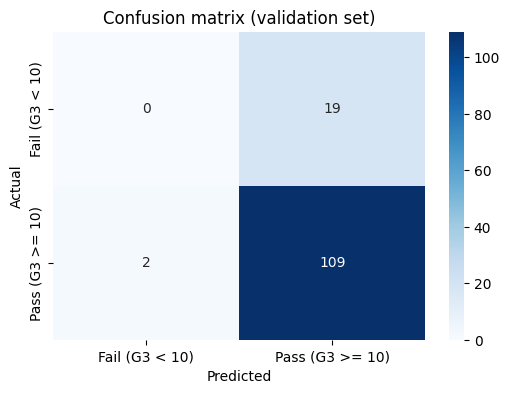

In [29]:
classes = ["Fail (G3 < 10)", "Pass (G3 >= 10)"]
mat = confusion_matrix(y_val, y_pred, labels=[0, 1])

df_cm = pd.DataFrame(mat, index=classes, columns=classes)

plt.figure(figsize=(6, 4))
sns.heatmap(df_cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix (validation set)")
plt.show()